<a href="https://colab.research.google.com/github/bibekgurau/CN6005/blob/main/week4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
import cv2

In [ ]:
# 1. Load and Preprocess CIFAR-10
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()
X_train, X_test = X_train / 255.0, X_test / 255.0

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 136s 1us/step


In [ ]:
# 2. Build Models
def build_model_with_pooling():
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3), name='conv1'),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='conv2'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation='relu', padding='same', name='target_conv'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ], name="CNN_With_Pooling")
    return model

def build_model_without_pooling():
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3), name='conv1'),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='conv2'),
        layers.Conv2D(128, (3, 3), activation='relu', padding='same', name='target_conv'),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ], name="CNN_Without_Pooling")
    return model

model_pool = build_model_with_pooling()
model_nopool = build_model_without_pooling()

model_pool.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_nopool.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Display Summaries
model_pool.summary()
model_nopool.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "CNN_With_Pooling"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ target_conv (Conv2D)            │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,242 (4.36 MB)

 Trainable params: 1,143,242 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

Model: "CNN_Without_Pooling"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ target_conv (Conv2D)            │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 131072)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    16,777,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,871,882 (64.36 MB)

 Trainable params: 16,871,882 (64.36 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
 # 3. Train Models
EPOCHS = 20
BATCH_SIZE = 64

print("\n--- Training Model 1 (With Pooling) ---")
history_pool = model_pool.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                              validation_data=(X_test, y_test))

print("\n--- Training Model 2 (Without Pooling) ---")
history_nopool = model_nopool.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                                validation_data=(X_test, y_test))


--- Training Model 1 (With Pooling) ---
Epoch 1/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 368s 471ms/step - accuracy: 0.6873 - loss: 0.8940 - val_accuracy: 0.7113 - val_loss: 0.8314
Epoch 2/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 380s 468ms/step - accuracy: 0.7525 - loss: 0.7142 - val_accuracy: 0.7138 - val_loss: 0.8293
Epoch 3/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 362s 463ms/step - accuracy: 0.7968 - loss: 0.5793 - val_accuracy: 0.7353 - val_loss: 0.7631
Epoch 4/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 365s 467ms/step - accuracy: 0.8359 - loss: 0.4692 - val_accuracy: 0.7436 - val_loss: 0.7933
Epoch 5/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 364s 466ms/step - accuracy: 0.8695 - loss: 0.3642 - val_accuracy: 0.7457 - val_loss: 0.8079
Epoch 6/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 382s 466ms/step - accuracy: 0.9050 - loss: 0.2704 - val_accuracy: 0.7391 - val_loss: 0.9395
Epoch 7/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 380s 463ms/step - accuracy: 0.9294 - loss: 0.1989 - val_accuracy: 0.7441 - val_loss: 1.0205
Epoch 8/20
782/782 ━━━━━━━━━━━━━━━━

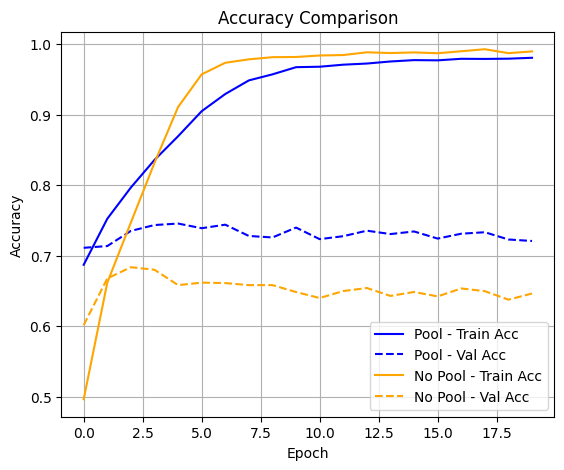

In [6]:
# 4. Plot Training/Validation Curves
plt.figure(figsize=(14, 5))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(history_pool.history['accuracy'], label='Pool - Train Acc', color='blue')
plt.plot(history_pool.history['val_accuracy'], label='Pool - Val Acc', color='blue', linestyle='--')
plt.plot(history_nopool.history['accuracy'], label='No Pool - Train Acc', color='orange')
plt.plot(history_nopool.history['val_accuracy'], label='No Pool - Val Acc', color='orange', linestyle='--')
plt.title('Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

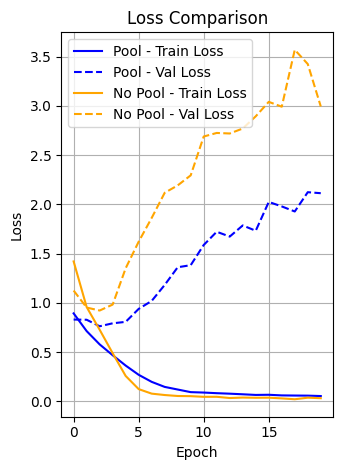

In [7]:
# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(history_pool.history['loss'], label='Pool - Train Loss', color='blue')
plt.plot(history_pool.history['val_loss'], label='Pool - Val Loss', color='blue', linestyle='--')
plt.plot(history_nopool.history['loss'], label='No Pool - Train Loss', color='orange')
plt.plot(history_nopool.history['val_loss'], label='No Pool - Val Loss', color='orange', linestyle='--')
plt.title('Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('accuracy_loss_comparison.png')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


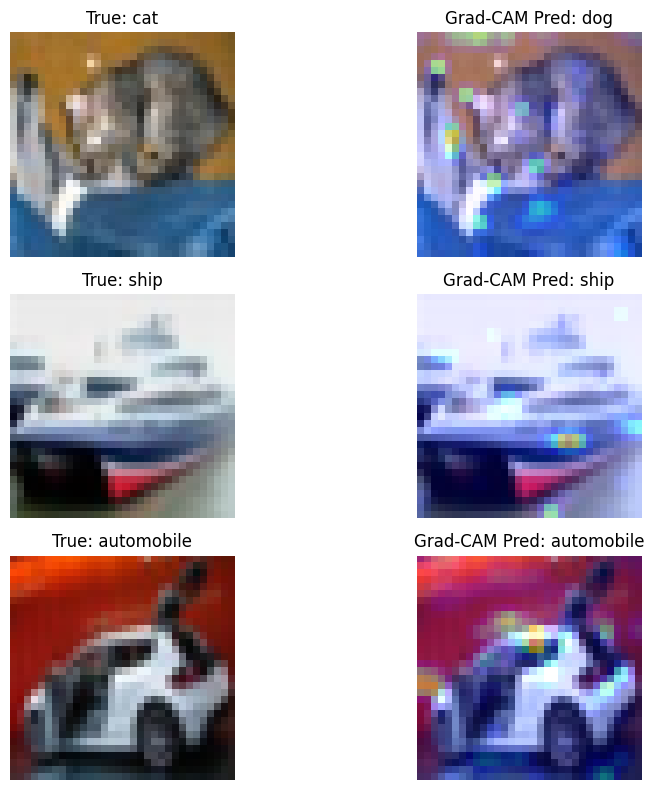

In [11]:
# 5. Grad-CAM Implementation
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # In Keras 3, we can create a sub-model by mapping model.input to outputs.
    # To avoid the 'not called/built' issue, we can construct the sub-model dynamically
    # or build the model explicitly. Since model_pool is Sequential, we can look up the layer:
    sub_input = tf.keras.Input(shape=model.input_shape[1:])
    x = sub_input

    # Reconstruct the forward path symbolically to get both intermediate and final outputs safely
    target_output = None
    for layer in model.layers:
        x = layer(x)
        if layer.name == last_conv_layer_name:
            target_output = x

    grad_model = tf.keras.models.Model(inputs=sub_input, outputs=[target_output, x])

    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

def display_gradcam(img, heatmap, alpha=0.4):
    heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0
    superimposed_img = heatmap * alpha + img
    return np.clip(superimposed_img, 0, 1)

# Generate sample Grad-CAM outputs
sample_indices = [0, 1, 6]  # Test sample indices
plt.figure(figsize=(10, 8))

for idx, sample_idx in enumerate(sample_indices):
    img = X_test[sample_idx]
    img_tensor = np.expand_dims(img, axis=0)

    # Prediction
    preds = model_pool.predict(img_tensor)
    pred_class = class_names[np.argmax(preds)]

    # Heatmap
    heatmap = make_gradcam_heatmap(img_tensor, model_pool, 'target_conv')
    gradcam_overlay = display_gradcam(img, heatmap)

    # Plot original
    plt.subplot(len(sample_indices), 2, idx * 2 + 1)
    plt.imshow(img)
    plt.title(f"True: {class_names[y_test[sample_idx][0]]}")
    plt.axis('off')

    # Plot Grad-CAM
    plt.subplot(len(sample_indices), 2, idx * 2 + 2)
    plt.imshow(gradcam_overlay)
    plt.title(f"Grad-CAM Pred: {pred_class}")
    plt.axis('off')

plt.tight_layout()
plt.savefig('gradcam_samples.png')
plt.show()